# 02 · MODIS reproduction: satellite features

**Purpose.** In notebook 01 assesses *what a pixel was labelled*, not *what the vegetation was actually doing*. 
The intern's next step added satellite measurements of vegetation state, so a model can see, for example, that a pixel labelled savanna is already as sparse as grassland and is likely to be relabelled.

This notebook **downloads and checks those measurements**. Notebook 03 trains the models that use them.

| Source | What | When | Why |
|---|---|---|---|
| **MODIS MOD13A1** (Terra, 500 m, 16-day) | NDVI and EVI, 12 periods per year | Every period of 2005, 2010, 2015 | The seasonal cycle separates savanna, grassland, woody savanna and cropland |
| **Landsat** Collection 2, Level 2 (30 m) | Red, NIR, two SWIR bands; NDVI, NDMI, NBR | January–April (dry season) of 2005, 2010, 2015 | Finer detail and moisture/burn signals; the dry season has the fewest clouds |

**No information from the future.** Features for a forecast starting in year *Y*
use only data from year *Y* and earlier. The 2020 land-cover map, the forecast
target, never informs a feature.

**Source:** Microsoft Planetary Computer's public archive. Each scene is clipped to Guinea and cached.

In [1]:
import sys; sys.path.insert(0, "../scripts")              # shared code: landuse_experiments/scripts/
import nb_helpers as H
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt, rasterio
from matplotlib.colors import LinearSegmentedColormap

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "figure.facecolor": H.SURFACE})
RERUN = {"modis": False,    # ~7 min, 144 composites
         "landsat": False}  # ~55 min, 107 scenes
YEARS = (2005, 2010, 2015)

# One-hue sequential ramp (reference palette, blue 100 -> 700) for continuous maps.
SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
SEQ.set_bad("#ffffff")

def read_stack(path):
    with rasterio.open(path) as src:
        data = src.read().astype("float32")
        if src.nodata is not None:
            data[data == src.nodata] = np.nan
        return data, list(src.descriptions)

## 1 · MODIS seasonal vegetation (NDVI, EVI)

Twelve 16-day composites per year, chosen as the ones closest to days 8, 38, 68 …
338, on the four MODIS tiles that cover Guinea (4 × 12 = 48 per year). Each
composite's own quality flags remove cloud, cloud shadow, high aerosol and snow
*before* it is resampled to the land-cover grid. A cloudy period is left missing.

In [2]:
modis_dir = H.ensure_run("local_landuse.modis_phenology", "modis",
                         ["--years", *map(str, YEARS)], RERUN["modis"], base="data")
intern_modis = {2005: (99.91, 96.02), 2010: (99.91, 94.90), 2015: (99.89, 94.81)}
rows, period_cov = [], {}
for y in YEARS:
    m = json.loads((modis_dir / str(y) / "manifest.json").read_text())
    period_cov[y] = 100 * np.array(m["period_coverage"])
    rows.append((y, f"{m['completed']}/{m['requested']}", len(m["failed"]),
                 100 * m["coverage_any"], intern_modis[y][0],
                 100 * m["coverage_six_periods"], intern_modis[y][1]))
H.show(pd.DataFrame(rows, columns=["Year", "Composites", "Failed",
                                   "≥1 usable period %", "Intern %", "≥6 usable periods %", "Intern % "]))

Using saved: data/modis


Year,Composites,Failed,≥1 usable period %,Intern %,≥6 usable periods %,Intern %
2005,48/48,0,99.91,99.91,96.02,96.02
2010,48/48,0,99.91,99.91,94.90,94.90
2015,48/48,0,99.89,99.89,94.81,94.81


Coverage matches the intern's table to two decimals in every year. Nearly every
pixel has at least one clear observation, and about 95% have six or more. The
gaps are concentrated in the rainy season:

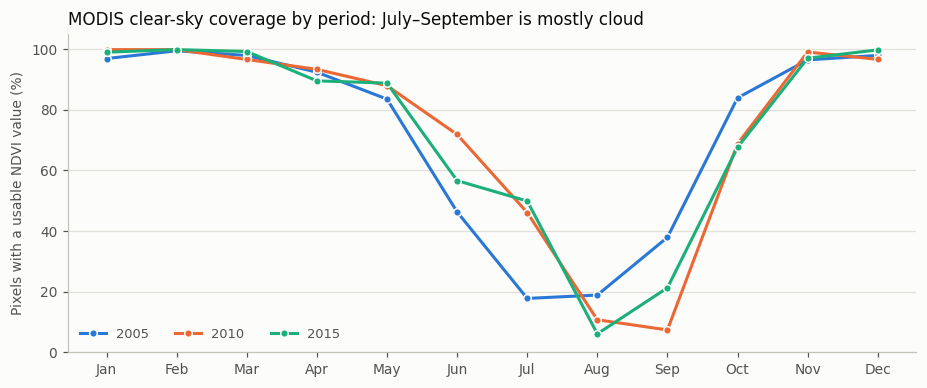

In [3]:
target_days = json.loads((modis_dir / "2015" / "manifest.json").read_text())["target_days"]
months = pd.to_datetime([f"2015-{d:03d}" for d in target_days], format="%Y-%j").strftime("%b")
fig, ax = plt.subplots(figsize=(8.5, 3.6))
for colour, y in zip(H.SERIES, YEARS):
    ax.plot(range(12), period_cov[y], color=colour, linewidth=2, marker="o", markersize=5,
            markeredgecolor=H.SURFACE, label=str(y))
ax.set_xticks(range(12), months)
ax.set_ylim(0, 105)
ax.set_ylabel("Pixels with a usable NDVI value (%)", color=H.INK_2)
H.style_axes(ax); ax.grid(axis="y", color=H.GRID, linewidth=0.8); ax.grid(axis="x", visible=False)
ax.set_title("MODIS clear-sky coverage by period: July–September is mostly cloud",
             loc="left", color=H.INK, fontsize=11)
ax.legend(frameon=False, ncol=3, loc="lower left", fontsize=8.5, labelcolor=H.INK_2)
plt.tight_layout(); plt.show()

**Why the seasonal cycle helps.** The three classes that hold most of the
observed change, and most false alarms, have different seasonal NDVI curves.
Woody savanna stays greenest, grassland dries out most, and savanna sits between
them. A pixel whose curve looks like a *different* class from its label is a
candidate for relabelling. The intern turned this idea into "class typicality"
features (notebook 03).

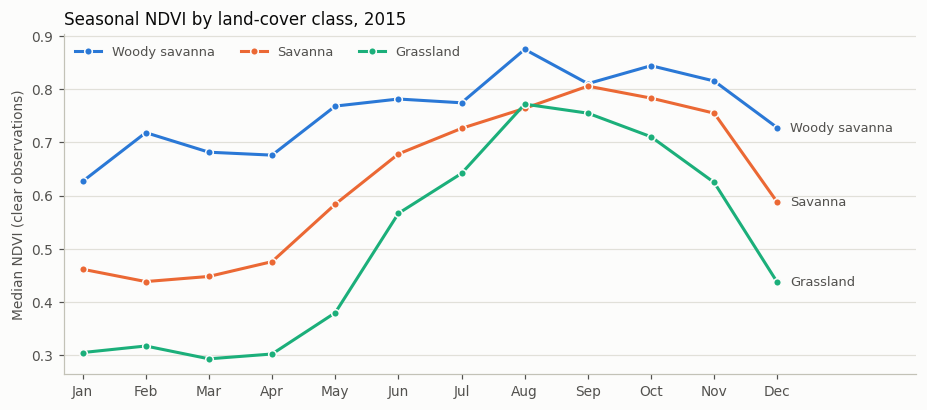

In [4]:
veg15, names = read_stack(modis_dir / "2015" / "seasonal_vegetation.tif")
ndvi = veg15[[names.index(f"ndvi_period_{i:02d}") for i in range(1, 13)]]
lc15, _ = H.read_map("Guinea_LandCover_2015.tif")
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for colour, code_ in zip(H.SERIES, (8, 9, 10)):
    sel = lc15 == code_
    median = np.nanmedian(ndvi[:, sel], axis=1)
    ax.plot(range(12), median, color=colour, linewidth=2, marker="o", markersize=5,
            markeredgecolor=H.SURFACE, label=H.IGBP[code_])
    ax.text(11.2, median[-1], H.IGBP[code_], color=H.INK_2, va="center", fontsize=8.5)
ax.set_xticks(range(12), months); ax.set_xlim(-0.3, 13.2)
ax.set_ylabel("Median NDVI (clear observations)", color=H.INK_2)
H.style_axes(ax); ax.grid(axis="y", color=H.GRID, linewidth=0.8); ax.grid(axis="x", visible=False)
ax.set_title("Seasonal NDVI by land-cover class, 2015", loc="left", color=H.INK, fontsize=11)
ax.legend(frameon=False, ncol=3, loc="upper left", fontsize=8.5, labelcolor=H.INK_2)
plt.tight_layout(); plt.show()

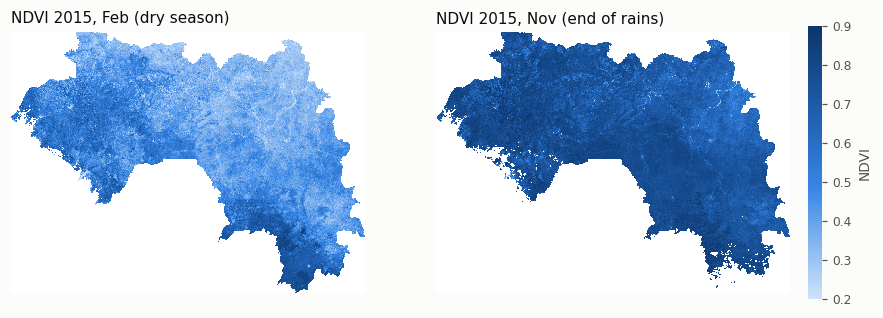

In [5]:
dry, wet = names.index("ndvi_period_02"), names.index("ndvi_period_11")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, band, label in zip(axes, (dry, wet), (f"{months[1]} (dry season)", f"{months[10]} (end of rains)")):
    im = ax.imshow(np.ma.masked_invalid(veg15[band]), cmap=SEQ, vmin=0.2, vmax=0.9, interpolation="nearest")
    ax.set_axis_off(); ax.set_title(f"NDVI 2015, {label}", loc="left", color=H.INK, fontsize=10)
cbar = fig.colorbar(im, ax=axes, shrink=0.7, pad=0.02); cbar.set_label("NDVI", color=H.INK_2)
cbar.outline.set_visible(False); cbar.ax.tick_params(colors=H.INK_2, labelsize=8)
plt.show()

## 2 · Landsat dry-season reflectance

Up to two low-cloud January–April scenes per Landsat path/row. Each scene's own
quality band screens cloud and shadow at 30 m before averaging to the 500 m grid.
Three different satellites are needed across the years:

* **2005: Landsat 7.** No Landsat 5 scenes exist for Guinea that year. Landsat 7's
  scan-line corrector failed in 2003, leaving stripes of missing data, so 2005
  coverage is lowest. Gaps are masked, never interpolated.
* **2010: Landsat 5. 2015: Landsat 8.**

Sensor differences between years are a possible source of error when a model
fitted on one year forecasts from another. The intern lists this as a caveat.

In [6]:
landsat_dir = H.ensure_run("local_landuse.landsat_features", "landsat",
                           ["--years", *map(str, YEARS)], RERUN["landsat"], base="data")
intern_landsat = {2005: ("34/34", 93.18), 2010: ("35/35", 97.21), 2015: ("38/38", 99.22)}
rows = []
for y in YEARS:
    m = json.loads((landsat_dir / str(y) / "manifest.json").read_text())
    rows.append((y, ", ".join(m["platforms"]), f"{m['completed_scenes']}/{m['requested_scenes']}",
                 intern_landsat[y][0], 100 * m["land_coverage_fraction"], intern_landsat[y][1]))
H.show(pd.DataFrame(rows, columns=["Year", "Satellite", "Scenes", "Intern scenes",
                                   "Land covered %", "Intern %"]))

Using saved: data/landsat


Year,Satellite,Scenes,Intern scenes,Land covered %,Intern %
2005,landsat-7,34/34,34/34,93.18,93.18
2010,landsat-5,35/35,35/35,97.21,97.21
2015,landsat-8,38/38,38/38,99.22,99.22


Same scenes and same coverage as the intern's run, which shows the scene
selection is deterministic. The maps below show dry-season NDVI from each
sensor. White areas have no clear observation: Landsat 7's stripes in 2005, and
cloud.

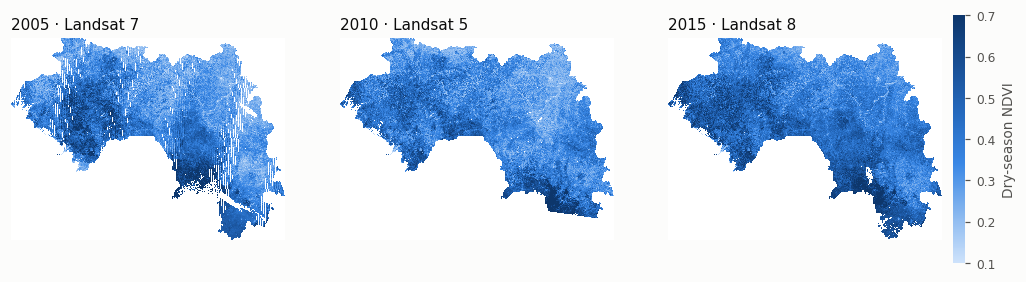

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, y in zip(axes, YEARS):
    stack, bands = read_stack(landsat_dir / str(y) / "landsat_dry_season.tif")
    m = json.loads((landsat_dir / str(y) / "manifest.json").read_text())
    im = ax.imshow(np.ma.masked_invalid(stack[bands.index("mean_ndvi")]), cmap=SEQ, vmin=0.1, vmax=0.7,
                   interpolation="nearest")
    ax.set_axis_off()
    ax.set_title(f"{y} · {m['platforms'][0].replace('landsat-', 'Landsat ')}", loc="left", color=H.INK, fontsize=10)
cbar = fig.colorbar(im, ax=axes, shrink=0.75, pad=0.01); cbar.set_label("Dry-season NDVI", color=H.INK_2)
cbar.outline.set_visible(False); cbar.ax.tick_params(colors=H.INK_2, labelsize=8)
plt.show()

## 3 · What the models receive

Notebook 03 turns these rasters into predictors. For each pixel and starting
year:

* **MODIS** (`phenology_models`): the 24 period values with missing-value flags;
  annual, wet- and dry-season means; a fitted annual harmonic; the same from five
  years earlier and the five-year trend.
* **MODIS neighbourhood** (`vegetation_context`): those seasonal means averaged
  over 3×3 and 15×15 windows, local variability and contrast.
* **Landsat** (`spectral_models`): the 15 bands above, an older observation, the
  trend, and neighbourhood statistics.
* **Combined** (`vegetation_context` with both): everything together.
* **Class typicality** (`class_typicality`): how well a pixel's seasonal curve
  fits the class it is labelled, estimated only from pixels whose label had
  already been stable for five years.

Download directory:

```
landuse_experiments/data/
  modis/<year>/     scenes/ (48 clipped composites) · seasonal_vegetation.tif · manifest.json
  landsat/<year>/   scenes/ (34–38 clipped scenes)  · landsat_dry_season.tif   · manifest.json
```

In [8]:
size = lambda p: sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) / 1e6
for d in (modis_dir, landsat_dir):
    for y in YEARS:
        m = json.loads((d / str(y) / "manifest.json").read_text())
        digest = m.get("sha256") or m.get("composite_sha256")
        print(f"{d.name:20s} {y}  {size(d / str(y)):6.0f} MB  feature raster sha256 {digest[:12]}")

modis                2005     113 MB  feature raster sha256 16f709708fdc
modis                2010     112 MB  feature raster sha256 3fbe957c565a
modis                2015     112 MB  feature raster sha256 ab3ec254c4c9
landsat              2005      99 MB  feature raster sha256 e87134e7003a
landsat              2010     109 MB  feature raster sha256 0184eb5a43b4
landsat              2015     117 MB  feature raster sha256 97e7d7e7b62b
